In [1]:
import sys

# Append the parent dir to search path to allow imports from src
sys.path.append('..')

# NOTE: In a real Python file instead use the line below
# sys.path.append(str(Path(__file__).resolve().parent.parent))

# Tell the Notebook to reload changed code in own packages automatically
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

TRAIN_PATH = Path('../data/raw/train_images/')
TEST_PATH = Path('../data/raw/test_images/')
LABELS_PATH = Path('../data/raw/train.csv')

# The checkpoint and, next to it, the per-epoch training curves. Defined here
# rather than in the save cell so the plotting and evaluation cells further down
# can reach them after a kernel restart, without re-running the training.
MODEL_PATH = Path('../models/pspnet_resnet34_binary.pth')
HISTORY_PATH = MODEL_PATH.with_name(f'{MODEL_PATH.stem}_history.json')


## Augmentation pipeline

In [3]:
import albumentations as A

pipeline = A.Compose(
    [
        A.HorizontalFlip(p=0.3),
        A.VerticalFlip(p=0.3),
        A.RandomBrightnessContrast(p=0.8),
        A.Rotate(p=0.6),
    ]
)


## PSPNet for binary image segmentation

After training it should detect if a new image contains any of the 4 cloud types.

In [4]:
import segmentation_models_pytorch as smp

model_pspnet = smp.PSPNet(
    encoder_name='resnet34', encoder_weights='imagenet', classes=4
)


## Dataset and DataLoader

`CloudSegmentationDataset` wraps `CloudSegmentationImage`: for every unique
image in `LABELS_PATH` it decodes the per-label masks, runs the `pipeline`
augmentation on the image/masks pair, and returns normalized tensors ready
for the model.

The image list is split into train/validation *before* wrapping it in two
dataset instances, so the same augmentation pipeline is used for training
while validation always sees the un-augmented image.

In [5]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

from src.data.cloud_segmentation_dataset import CloudSegmentationDataset
from src.data.labels import load_processed_labels

labels_df = load_processed_labels(LABELS_PATH)

# Get all image names.
#
# NOTE: Every image has 4 rows in labels_df, so `.unique()` must be called to
# only get one item of every name. Additionally `.tolist()` is called to convert
# the result from type `ArrowStringArray`, which `train_test_split()` doesn't
# understand, to a list.
image_names = labels_df['Image'].unique().tolist()

# Split by the unique image name. So all 4 label rows of an image end up on the
# same side of the split (no leakage between train and validation).
#
# NOTE: `test_size` and `random_state` match the UNet-ResNet50 notebook
# (`Shari_UNet_ResNet50.ipynb`). Both notebooks build their image list from the
# same `train.csv` in the same order, so these two values make the validation
# set *identical* (555 images) - which is what makes the two models' scores
# comparable in the report.
train_image_names, val_image_names = train_test_split(
    image_names, test_size=0.1, random_state=42
)

train_labels_df = labels_df[labels_df['Image'].isin(train_image_names)]
val_labels_df = labels_df[labels_df['Image'].isin(val_image_names)]

train_dataset = CloudSegmentationDataset(
    train_labels_df, TRAIN_PATH, pipeline=pipeline
)

# No augmentation for validation, so it reflects real-world performance
val_dataset = CloudSegmentationDataset(val_labels_df, TRAIN_PATH, pipeline=None)

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print(
    f'Train images: {len(train_dataset)}, validation images: {len(val_dataset)}'
)


Train images: 4991, validation images: 555


## Loss, optimizer, device

A pixel can belong to several cloud types at once (see
`CloudSegmentationImage.get_mask_stack`), so this is a **multi-label**
problem: each of the 4 output channels is an independent binary mask, not a
single softmax over 4 classes. The loss combines `BCEWithLogitsLoss` (per-pixel,
per-channel) with a multilabel Dice loss (rewards overlap of the predicted
and true mask regions), which is a common combination for segmentation.

In [6]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_pspnet = model_pspnet.to(device)

bce_loss = torch.nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode='multilabel', from_logits=True)


def criterion(logits, masks):
    return bce_loss(logits, masks) + dice_loss(logits, masks)


optimizer = torch.optim.Adam(model_pspnet.parameters(), lr=1e-4)

print(f'Using device: {device}')


Using device: cuda


## Train the model

Alongside the loss, Dice and IoU are tracked per epoch (see
`src.models.metrics.SegmentationStats`). The loss is `BCE + Dice loss`, the
quantity the optimizer minimizes - it is not a score that can be reported as
"Dice", so the metrics are computed separately on the thresholded 0/1 masks.

`history` stores the **macro** aggregation (one score per cloud type, then
averaged), so a rare cloud type counts as much as a common one. The training
scores are accumulated from the logits of the update steps: within an epoch the
weights keep changing and the images are augmented, so those are a running
average over a moving model. Only the validation numbers describe a fixed model
on untouched images.

In [7]:
from tqdm.auto import tqdm

from src.models.metrics import SegmentationStats

NUM_EPOCHS = 25

history = {
    'train_loss': [],
    'val_loss': [],
    'train_dice': [],
    'val_dice': [],
    'train_iou': [],
    'val_iou': [],
}

for epoch in range(NUM_EPOCHS):
    # --- Train ---
    model_pspnet.train()
    train_loss = 0.0
    train_stats = SegmentationStats()
    for images, masks in tqdm(
        train_loader, desc=f'Epoch {epoch + 1}/{NUM_EPOCHS} [train]'
    ):
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model_pspnet(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        # Scored on the logits the update step computed anyway, so tracking the
        # metrics costs no extra forward pass.
        train_stats.update(logits, masks)
    train_loss /= len(train_dataset)
    train_scores = train_stats.scores()

    # --- Validate ---
    model_pspnet.eval()
    val_loss = 0.0
    val_stats = SegmentationStats()
    with torch.no_grad():
        for images, masks in tqdm(
            val_loader, desc=f'Epoch {epoch + 1}/{NUM_EPOCHS} [val]'
        ):
            images, masks = images.to(device), masks.to(device)
            logits = model_pspnet(images)
            loss = criterion(logits, masks)
            val_loss += loss.item() * images.size(0)

            val_stats.update(logits, masks)
    val_loss /= len(val_dataset)
    val_scores = val_stats.scores()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_dice'].append(train_scores['dice_macro'])
    history['val_dice'].append(val_scores['dice_macro'])
    history['train_iou'].append(train_scores['iou_macro'])
    history['val_iou'].append(val_scores['iou_macro'])

    train_dice = train_scores['dice_macro']
    val_dice = val_scores['dice_macro']
    val_iou = val_scores['iou_macro']
    print(
        f'Epoch {epoch + 1}/{NUM_EPOCHS} - '
        f'train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} - '
        f'train_dice: {train_dice:.4f} - val_dice: {val_dice:.4f} - '
        f'val_iou: {val_iou:.4f}'
    )


Epoch 1/25 [train]:   0%|          | 0/624 [00:00<?, ?it/s]

c:\Users\uwero\REPOS\Python\jun26_bcds_cloud_segmentation\notebooks\..\src\data\cloud_segmentation_dataset.py:103: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  image_tensor = torch.from_numpy(np.ascontiguousarray(image))


Epoch 1/25 [val]:   0%|          | 0/70 [00:00<?, ?it/s]

Epoch 1/25 - train_loss: 0.9038 - val_loss: 0.8838 - train_dice: 0.4797 - val_dice: 0.5338 - val_iou: 0.3674


Epoch 2/25 [train]:   0%|          | 0/624 [00:00<?, ?it/s]

...

Epoch 24/25 [val]:   0%|          | 0/70 [00:00<?, ?it/s]

Epoch 24/25 - train_loss: 0.7515 - val_loss: 0.7911 - train_dice: 0.5901 - val_dice: 0.5985 - val_iou: 0.4312


Epoch 25/25 [train]:   0%|          | 0/624 [00:00<?, ?it/s]

Epoch 25/25 [val]:   0%|          | 0/70 [00:00<?, ?it/s]

Epoch 25/25 - train_loss: 0.7524 - val_loss: 0.7823 - train_dice: 0.5927 - val_dice: 0.6039 - val_iou: 0.4357


## Save the trained model

The checkpoint stores the weights only, so `history` - which lives in the kernel
and nowhere else - is written next to it as JSON. That keeps the training curves
below reproducible after a kernel restart, without re-running the training cell.


In [8]:
import json

import torch

torch.save(model_pspnet.state_dict(), MODEL_PATH)
HISTORY_PATH.write_text(json.dumps(history, indent=2))


3735

## Training curves

Both curves come from the same `history`, so they share the x axis: the loss
that was optimized, and the Dice score that is reported. Every epoch is drawn,
but only every second one is labeled on the x axis - which also thins out the
vertical grid lines, since matplotlib draws them at the ticks.

Like the evaluation cell further down, this section works without re-running the
training: if `history` isn't in the kernel, it is read back from `HISTORY_PATH`.


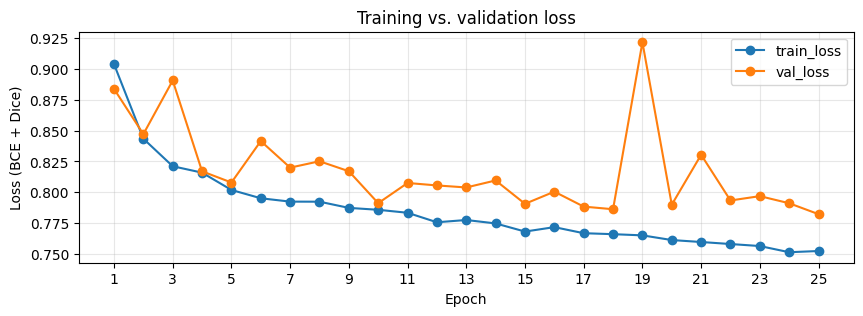

In [9]:
import json

import matplotlib.pyplot as plt

# `history` only exists in the kernel. If the training cell wasn't run in this
# session, fall back to the JSON the save cell wrote - the curves then come from
# the same run as the checkpoint, with no re-training.
if 'history' not in globals():
    history = json.loads(HISTORY_PATH.read_text())

epochs = range(1, len(history['train_loss']) + 1)

# Every epoch is plotted, only every second one is labeled. Matplotlib draws
# the vertical grid lines at the ticks, so thinning the ticks thins the grid
# with them - the curves keep all data points.
epoch_ticks = epochs[::2]

# Wide and flat, in inches. Shared by both training curves so they have the
# same shape in the report.
FIGSIZE = (10, 3)

plt.figure(figsize=FIGSIZE)
plt.plot(epochs, history['train_loss'], marker='o', label='train_loss')
plt.plot(epochs, history['val_loss'], marker='o', label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (BCE + Dice)')
plt.title('Training vs. validation loss')
plt.xticks(epoch_ticks)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


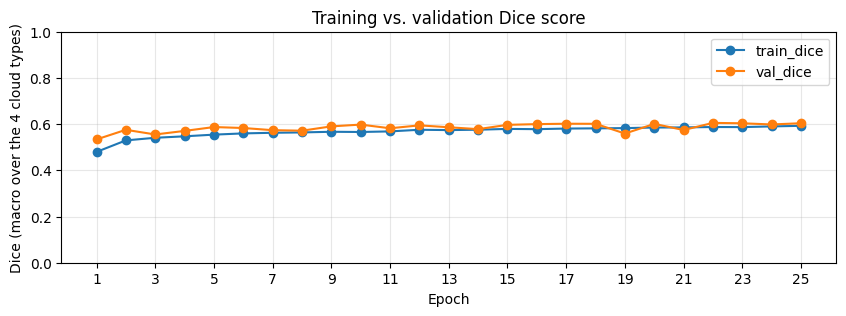

In [10]:
epochs = range(1, len(history['train_dice']) + 1)
epoch_ticks = epochs[::2]

plt.figure(figsize=FIGSIZE)
plt.plot(epochs, history['train_dice'], marker='o', label='train_dice')
plt.plot(epochs, history['val_dice'], marker='o', label='val_dice')
plt.xlabel('Epoch')
plt.ylabel('Dice (macro over the 4 cloud types)')
plt.title('Training vs. validation Dice score')
plt.xticks(epoch_ticks)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Validation metrics of the trained model

The numbers below are the final scores of the saved checkpoint - the ones to
quote in the report. They are computed on the thresholded 0/1 masks the model
actually outputs (threshold `0.5`, the same one `predict_mask_stack` uses), not
on the loss.

Two aggregations are reported because they say different things on this
dataset: **micro** pools the pixels of all 4 cloud types and is therefore
dominated by the large ones, while **macro** averages the 4 per-type scores and
weighs a rare cloud type as much as a common one. The per-type table shows
where the difference comes from.

This cell scores the checkpoint from `MODEL_PATH` rather than the
`model_pspnet` object, so it also produces the metrics for an already trained
model without re-running the training cell.

In [11]:
import pandas as pd
from IPython.display import display

from src.models.metrics import evaluate_model
from src.models.predict_model import load_pspnet

trained_model = load_pspnet(MODEL_PATH, device)

val_stats, final_val_loss = evaluate_model(
    trained_model, val_loader, device, criterion=criterion
)
val_scores = val_stats.scores()

summary = pd.Series(
    {
        'val_loss (BCE + Dice)': final_val_loss,
        'val_dice (macro)': val_scores['dice_macro'],
        'val_dice (micro)': val_scores['dice_micro'],
        'val_iou (macro)': val_scores['iou_macro'],
        'val_iou (micro)': val_scores['iou_micro'],
    },
    name='value',
).round(4)

display(summary.to_frame())
display(val_stats.per_class_dataframe().round(4))


,value
val_loss (BCE + Dice),0.7823
val_dice (macro),0.6039
val_dice (micro),0.6074
val_iou (macro),0.4357
val_iou (micro),0.4362


,dice,iou
label,,
fish,0.5125,0.3446
flower,0.6947,0.5322
gravel,0.5829,0.4114
sugar,0.6253,0.4548


## Inference on unseen `TEST_PATH` images

`TEST_PATH` has no labels (no CSV), so `CloudSegmentationImage` can't decode
masks for it from a `DataFrame`. Instead, `predict_mask_stack()` runs the
trained model on a raw image and thresholds its output into a 0/1 mask stack
- the same shape `CloudSegmentationImage.get_mask_stack()` produces for
labeled images. That means `CloudSegmentationImage.from_image_and_masks()`
and therefore `display_masks_overlay()` work on model *predictions* just as
well as on ground truth.

Since a pixel/image can contain several cloud types at once (multi-label,
see above), "detected" below means: for that cloud type, the predicted mask
covers at least `MIN_DETECTION_AREA` pixels - not a single yes/no over the
whole image.

## 002f507.jpg - detected: **gravel, sugar**

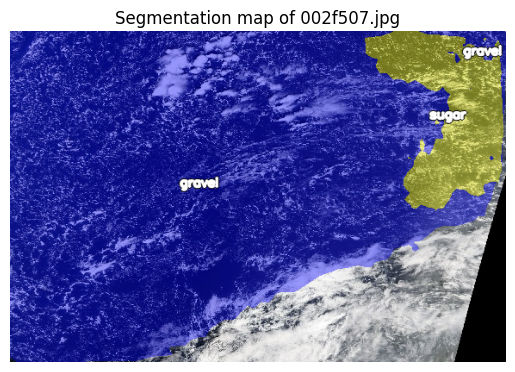

## 0035ae9.jpg - detected: **fish, gravel, sugar**

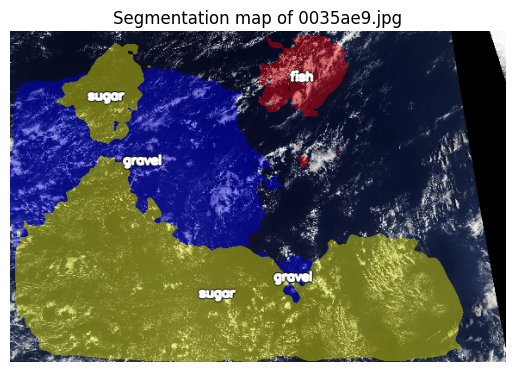

## 0038327.jpg - detected: **fish, flower, sugar**

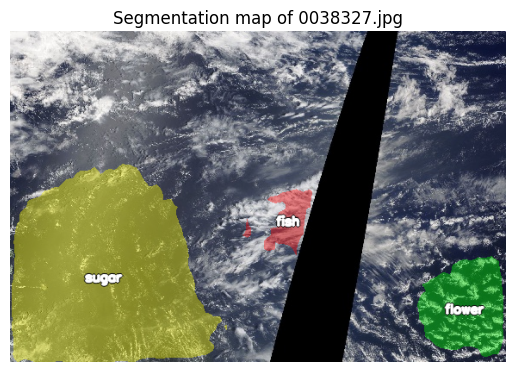

## 004f759.jpg - detected: **fish, flower, gravel, sugar**

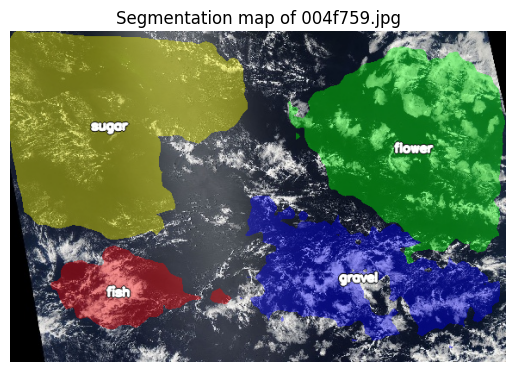

## 005ba08.jpg - detected: **gravel**

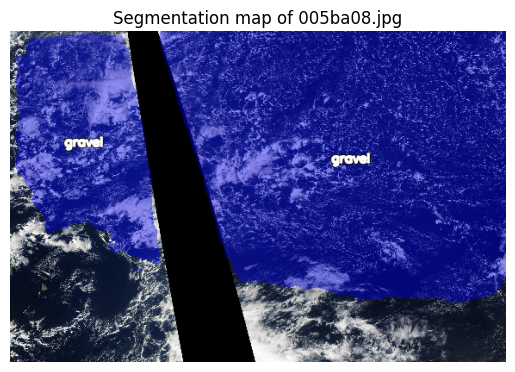

## 006440a.jpg - detected: **fish, gravel, sugar**

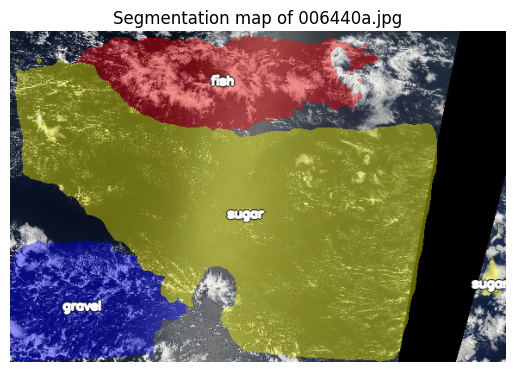

## 006f61b.jpg - detected: **fish, flower, sugar**

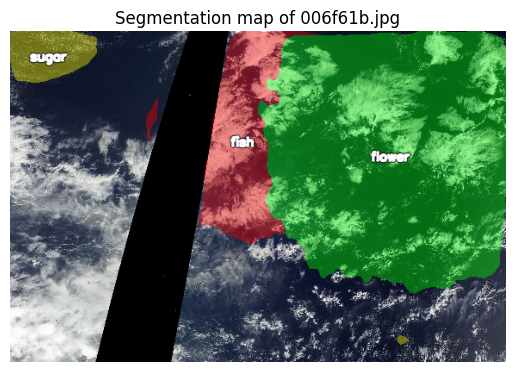

In [12]:
import cv2
from IPython.display import Markdown, display

from src.data.cloud_segmentation_image import (
    LABEL_CLASS_IDS,
    CloudSegmentationImage,
)
from src.models.predict_model import detected_labels, predict_mask_stack
from src.visualization.image_display import display_masks_overlay

NUM_TEST_IMAGES_TO_SHOW = 7
label_names = list(LABEL_CLASS_IDS.keys())

test_image_paths = sorted(TEST_PATH.iterdir())[:NUM_TEST_IMAGES_TO_SHOW]

for image_path in test_image_paths:
    image_bgr = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    mask_stack = predict_mask_stack(model_pspnet, image_rgb, device)
    labels = detected_labels(mask_stack, label_names)

    csi_pred = CloudSegmentationImage.from_image_and_masks(
        image_rgb=image_rgb,
        mask_stack=mask_stack,
        image_name=image_path.name,
        image_path=image_path.parent,
    )

    detected_str = ', '.join(labels) if labels else 'none'
    display(Markdown(f'## {image_path.name} - detected: **{detected_str}**'))
    display_masks_overlay(csi_pred)
